# Union-Find (conjuntos disjuntos)

Mantiene una partición de elementos en conjuntos con dos operaciones: `find` (representante del conjunto de un elemento) y `union` (fusionar dos conjuntos). Con compresión de caminos y unión por rango, cada operación cuesta casi $O(1)$ amortizado.

## 1. Implementación

Implementar una clase `UnionFind` con `find` (con compresión de caminos) y `union` (por rango) que devuelva si ha fusionado algo.

In [1]:
class UnionFind:
    def __init__(self, n):
        self.padre = list(range(n))
        self.rango = [0] * n

    def find(self, x):
        if self.padre[x] != x:
            # compresión: apunta directo a la raíz
            self.padre[x] = self.find(self.padre[x])
        return self.padre[x]

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra == rb:
            return False
        if self.rango[ra] < self.rango[rb]:
            ra, rb = rb, ra
        self.padre[rb] = ra
        self.rango[ra] += self.rango[ra] == self.rango[rb]
        return True

uf = UnionFind(6)
uf.union(0, 1)
uf.union(1, 2)
uf.union(3, 4)
print([uf.find(i) for i in range(6)])
print(uf.find(0) == uf.find(2), uf.find(0) == uf.find(3))

[0, 0, 0, 3, 3, 5]
True False


## 2. Componentes conexas

Dado un grafo no dirigido con $n$ nodos y una lista de aristas, contar sus componentes conexas.

In [2]:
def componentes(n, aristas):
    uf = UnionFind(n)
    return n - sum(uf.union(a, b) for a, b in aristas)

print(componentes(7, [(0, 1), (1, 2), (3, 4), (5, 6), (6, 5)]))

3


## 3. Detectar un ciclo

Decidir si un grafo no dirigido tiene ciclos: hay ciclo si una arista une dos nodos que ya estaban en el mismo conjunto.

In [3]:
def tiene_ciclo(n, aristas):
    uf = UnionFind(n)
    return any(not uf.union(a, b) for a, b in aristas)

print(tiene_ciclo(4, [(0, 1), (1, 2), (2, 3)]), tiene_ciclo(4, [(0, 1), (1, 2), (2, 0)]))

False True


## 4. Rango y compresión: medir alturas

Crear una variante con un contador de pasos en la que se puedan activar o desactivar la unión por rango y la compresión de caminos (con `find` iterativo, porque sin optimizar los árboles pueden ser más profundos que el límite de recursión). Con $n = 2000$, probar dos secuencias de uniones (unir $0$ con cada uno de los demás en orden, el peor caso para la unión ingenua, que forma una cadena, y uniones aleatorias), seguidas de $n$ `find` aleatorios, y comprobar los resultados contra la clase anterior. Comparar la altura máxima del bosque y los pasos de las cuatro combinaciones: con rango la altura es $O(\log n)$, y con las dos optimizaciones el coste amortizado es $O(\alpha(n))$, prácticamente constante.

en cadena  ingenua              altura  1999, pasos 3,989,646
en cadena  ingenua + compresión altura  1998, pasos     7,991
en cadena  rango                altura     1, pasos     2,000
en cadena  rango + compresión   altura     1, pasos     2,000
aleatorias ingenua              altura   351, pasos 1,336,819
aleatorias ingenua + compresión altura     4, pasos    19,394
aleatorias rango                altura     5, pasos    15,393
aleatorias rango + compresión   altura     2, pasos     8,998


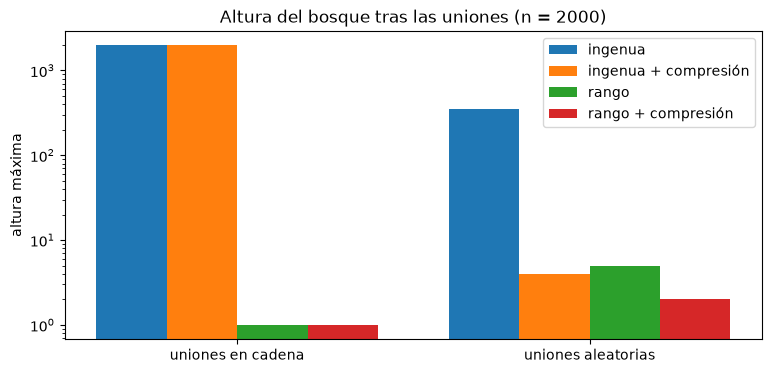

In [4]:
import random
import matplotlib.pyplot as plt

class UnionFindVariante:
    def __init__(self, n, rango=True, compresion=True):
        self.padre, self.rango = list(range(n)), [0] * n
        self.usa_rango, self.usa_compresion = rango, compresion
        self.pasos = 0

    def find(self, x):
        raiz = x
        while self.padre[raiz] != raiz:
            raiz = self.padre[raiz]
            self.pasos += 1
        if self.usa_compresion:
            while self.padre[x] != raiz:
                self.padre[x], x = raiz, self.padre[x]
        return raiz

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra == rb:
            return False
        if self.usa_rango:
            if self.rango[ra] < self.rango[rb]:
                ra, rb = rb, ra
            self.rango[ra] += self.rango[ra] == self.rango[rb]
            self.padre[rb] = ra
        else:
            self.padre[ra] = rb  # ingenua: la raíz de a cuelga de b
        return True

    def altura(self):
        def profundidad(x):
            d = 0
            while self.padre[x] != x:
                x, d = self.padre[x], d + 1
            return d
        return max(profundidad(x) for x in range(len(self.padre)))

n = 2000
random.seed(1)
escenarios = {
    "en cadena": [(0, i) for i in range(1, n)],
    "aleatorias": [(random.randrange(n), random.randrange(n)) for _ in range(2 * n)],
}
consultas = [random.randrange(n) for _ in range(n)]
alturas = {}
for escenario, uniones in escenarios.items():
    for rango in (False, True):
        for compresion in (False, True):
            uf, referencia = UnionFindVariante(n, rango, compresion), UnionFind(n)
            for a, b in uniones:
                assert uf.union(a, b) == referencia.union(a, b)
            nombre = ("rango" if rango else "ingenua") + (" + compresión" if compresion else "")
            alturas.setdefault(nombre, []).append(uf.altura())
            for x in consultas:
                uf.find(x)
            print(f"{escenario:10} {nombre:20} altura {alturas[nombre][-1]:5}, pasos {uf.pasos:>9,}")

fig, eje = plt.subplots(figsize=(9, 4))
ancho = 0.2
for k, (nombre, valores) in enumerate(alturas.items()):
    eje.bar([x + (k - 1.5) * ancho for x in range(len(escenarios))], valores, ancho, label=nombre)
eje.set_xticks(range(len(escenarios)), [f"uniones {e}" for e in escenarios])
eje.set(yscale="log", ylabel="altura máxima", title=f"Altura del bosque tras las uniones (n = {n})")
eje.legend()
plt.show()

## 5. Componente gigante

Añadir aristas aleatorias a un grafo de $n = 2000$ nodos y seguir, tras cada arista, el número de componentes y el tamaño de la mayor (guardando el tamaño de cada conjunto en su raíz). Comprobar el resultado final con un recorrido en anchura y dibujar cómo aparece de golpe una componente gigante cuando el número de aristas pasa de $n / 2$.

  500 aristas:  1500 componentes, la mayor con 15 nodos
 1000 aristas:  1001 componentes, la mayor con 196 nodos
 1500 aristas:   581 componentes, la mayor con 1182 nodos
 4000 aristas:    45 componentes, la mayor con 1953 nodos


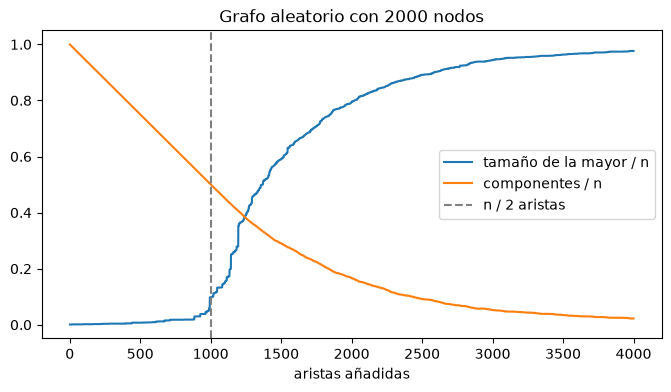

In [5]:
from collections import deque

def evolucion_componentes(n, aristas):
    uf, tamano = UnionFind(n), [1] * n
    componentes, mayor, historia = n, 1, []
    for a, b in aristas:
        ra, rb = uf.find(a), uf.find(b)
        if uf.union(a, b):
            raiz = uf.find(a)
            tamano[raiz] = tamano[ra] + tamano[rb]
            componentes -= 1
            mayor = max(mayor, tamano[raiz])
        historia.append((componentes, mayor))
    return historia

def componentes_bfs(n, aristas):
    vecinos = [[] for _ in range(n)]
    for a, b in aristas:
        vecinos[a].append(b)
        vecinos[b].append(a)
    visto, tamanos = [False] * n, []
    for inicio in range(n):
        if not visto[inicio]:
            visto[inicio], cola, tam = True, deque([inicio]), 0
            while cola:
                x = cola.popleft()
                tam += 1
                for y in vecinos[x]:
                    if not visto[y]:
                        visto[y] = True
                        cola.append(y)
            tamanos.append(tam)
    return len(tamanos), max(tamanos)

n = 2000
random.seed(2)
aristas = [(random.randrange(n), random.randrange(n)) for _ in range(2 * n)]
historia = evolucion_componentes(n, aristas)
for m in (500, 1000, 1500, 4000):
    assert historia[m - 1] == componentes_bfs(n, aristas[:m])
    print(f"{m:5} aristas: {historia[m - 1][0]:5} componentes, la mayor con {historia[m - 1][1]} nodos")

fig, eje = plt.subplots(figsize=(8, 4))
eje.plot(range(1, len(historia) + 1), [m / n for _, m in historia], label="tamaño de la mayor / n")
eje.plot(range(1, len(historia) + 1), [c / n for c, _ in historia], label="componentes / n")
eje.axvline(n / 2, color="gray", linestyle="--", label="n / 2 aristas")
eje.set(xlabel="aristas añadidas", title=f"Grafo aleatorio con {n} nodos")
eje.legend()
plt.show()

## 6. Percolación

En una rejilla de $n \times n$ casillas se van abriendo casillas al azar. El sistema percola cuando hay un camino de casillas abiertas (vecinas en horizontal o vertical) de la fila de arriba a la de abajo. Usar dos nodos virtuales, uno unido a toda la fila superior y otro a toda la inferior, para detectarlo con un solo `find`. Estimar con simulaciones la fracción de casillas abiertas en el momento de percolar (el umbral teórico es $\approx 0.5927$), comprobar con un recorrido en anchura que percola justo al abrir la última casilla y dibujar una rejilla al percolar.

umbral estimado con n = 50: 0.5923


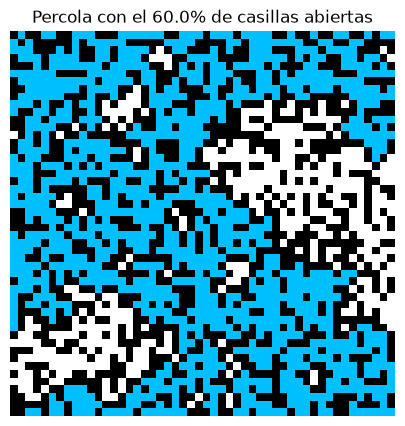

In [6]:
def percola_bfs(abierta, n):
    cola = deque((0, c) for c in range(n) if abierta[0][c])
    visto = {(0, c) for c in range(n) if abierta[0][c]}
    while cola:
        f, c = cola.popleft()
        if f == n - 1:
            return True
        for df, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            g, d = f + df, c + dc
            if 0 <= g < n and 0 <= d < n and abierta[g][d] and (g, d) not in visto:
                visto.add((g, d))
                cola.append((g, d))
    return False

def simula_percolacion(n, rng):
    uf = UnionFind(n * n + 2)
    arriba, abajo = n * n, n * n + 1
    abierta = [[False] * n for _ in range(n)]
    orden = [(f, c) for f in range(n) for c in range(n)]
    rng.shuffle(orden)
    for k, (f, c) in enumerate(orden, 1):
        abierta[f][c] = True
        if f == 0:
            uf.union(f * n + c, arriba)
        if f == n - 1:
            uf.union(f * n + c, abajo)
        for g, d in ((f + 1, c), (f - 1, c), (f, c + 1), (f, c - 1)):
            if 0 <= g < n and 0 <= d < n and abierta[g][d]:
                uf.union(f * n + c, g * n + d)
        if uf.find(arriba) == uf.find(abajo):
            return k / (n * n), abierta, uf, (f, c)

rng = random.Random(3)
for _ in range(20):
    n = rng.randint(2, 12)
    fraccion, abierta, _, (f, c) = simula_percolacion(n, rng)
    assert percola_bfs(abierta, n)
    abierta[f][c] = False
    assert not percola_bfs(abierta, n)

n = 50
rng = random.Random(4)
umbrales = [simula_percolacion(n, rng)[0] for _ in range(200)]
media = sum(umbrales) / len(umbrales)
print(f"umbral estimado con n = {n}: {media:.4f}")

fraccion, abierta, uf, _ = simula_percolacion(n, random.Random(5))
raiz_arriba = uf.find(n * n)
colores = [[2 if abierta[f][c] and uf.find(f * n + c) == raiz_arriba else int(abierta[f][c])
            for c in range(n)] for f in range(n)]
fig, eje = plt.subplots(figsize=(5, 5))
eje.imshow(colores, cmap=plt.matplotlib.colors.ListedColormap(["black", "white", "deepskyblue"]))
eje.set_title(f"Percola con el {fraccion:.1%} de casillas abiertas")
eje.axis("off")
plt.show()